# Kernel Stein discrepancy: estimators, failure cases and cost
For target score $s=\nabla\log\pi$, KSD averages a Stein kernel built from scores and first/mixed kernel derivatives. The V-statistic includes self terms and is nonnegative up to roundoff; the off-diagonal U-statistic estimates squared discrepancy and can be **negative**. [R15](../docs/references.md#r15), application [R01](../docs/references.md#r01).

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


In [2]:
from lafa.diagnostics import ksd
from lafa.kernels import RBF,IMQ
target=Gaussian([0,0],[[1,0],[0,1]],device=device,dtype=dtype)
counts=[32,64,128,256] if quick else [32,64,128,256,512,1024]
base=target.sample(max(counts),generator=gen())
samples={'correct':base,'shifted':base+tensor([1.2,0]),'wide variance':base*1.8}
rows=[]
for name,z in samples.items():
    for label,kernel in [('RBF',RBF(1.)),('IMQ',IMQ(1.,-.5))]:
        for size in counts:
            sync(); start=time.perf_counter()
            v=ksd(z[:size],target.score,kernel=kernel,estimator='v',block_size=64)
            u=ksd(z[:size],target.score,kernel=kernel,estimator='u',block_size=64)
            sync(); elapsed=time.perf_counter()-start
            rows.append(dict(sample=name,kernel=label,N=size,V_squared=float(v),signed_U_squared=float(u),seconds=elapsed))
table([r for r in rows if r['N']==counts[-1]])

| sample | kernel | N | V_squared | signed_U_squared | seconds |
|---|---|---|---|---|---|
| correct | RBF | 256 | 0.02064 | 0.00517 | 0.03174 |
| correct | IMQ | 256 | 0.02959 | 0.01416 | 0.03635 |
| shifted | RBF | 256 | 0.6246 | 0.6043 | 0.03233 |
| shifted | IMQ | 256 | 1.028 | 1.009 | 0.03334 |
| wide variance | RBF | 256 | 0.2195 | 0.1876 | 0.03037 |
| wide variance | IMQ | 256 | 0.2623 | 0.2305 | 0.03432 |

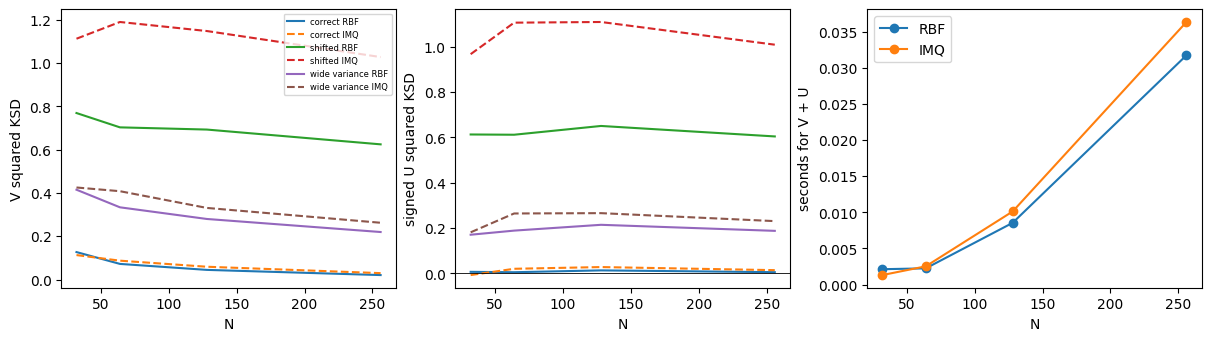

In [3]:
fig,ax=plt.subplots(1,3,figsize=(12,3.3),layout='constrained')
for name in samples:
    for k,ls in [('RBF','-'),('IMQ','--')]:
        rr=[r for r in rows if r['sample']==name and r['kernel']==k]
        ax[0].plot(counts,[r['V_squared'] for r in rr],ls,label=name+' '+k)
        ax[1].plot(counts,[r['signed_U_squared'] for r in rr],ls,label=name+' '+k)
ax[0].set(xlabel='N',ylabel='V squared KSD'); ax[1].set(xlabel='N',ylabel='signed U squared KSD'); ax[1].axhline(0,color='k',lw=.6)
for k in ['RBF','IMQ']:
    rr=[r for r in rows if r['sample']=='correct' and r['kernel']==k]; ax[2].plot(counts,[r['seconds'] for r in rr],'o-',label=k)
ax[2].set(xlabel='N',ylabel='seconds for V + U'); ax[0].legend(fontsize=6); ax[2].legend(); plt.show()

Each curve uses nested prefixes of one seeded sample and fixed bandwidths, so neighboring points are dependent. U-statistic unbiasedness requires independent draws and sample-independent masses; correlated chain outputs and interacting particles do not satisfy that condition. We retain signed U values rather than clipping or taking their square root.

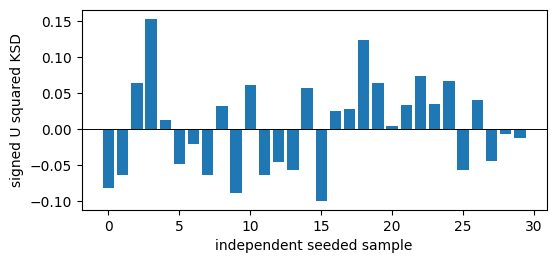

Negative null U estimates: 14 of 30


In [4]:
# Display real negative null estimates across independent small samples.
null_u=[]
for j in range(30):
    z=target.sample(24,generator=gen(100+j)); null_u.append(float(ksd(z,target.score,kernel=IMQ(),estimator='u',block_size=16)))
fig,ax=plt.subplots(figsize=(6,2.6)); ax.bar(range(len(null_u)),null_u); ax.axhline(0,color='k',lw=.7)
ax.set(xlabel='independent seeded sample',ylabel='signed U squared KSD'); plt.show()
print('Negative null U estimates:',sum(v<0 for v in null_u),'of',len(null_u))

In [5]:
mix=GaussianMixture2D(device=device,dtype=dtype)
def score_mix(z):
    with torch.enable_grad():
        leaf=z.detach().requires_grad_(); return -torch.autograd.grad(mix(leaf).sum(),leaf)[0].detach()
correct=mix.sample(256,generator=gen(200))
missing=mix.means[0]+torch.randn((256,2),device=device,dtype=dtype,generator=gen(201))*.5**.5
mode_rows=[]
for name,z in [('all modes IID',correct),('single mode only',missing)]:
    mode_rows.append(dict(sample=name,RBF_V=float(ksd(z,score_mix,kernel=RBF())),IMQ_V=float(ksd(z,score_mix,kernel=IMQ())),mean_error=float((z.mean(0)-mix.mean).norm())))
table(mode_rows)
# Tiling retains every pair; verify dense-equivalent answers across tile sizes.
a=ksd(base[:128],target.score,kernel=IMQ(),block_size=16)
b=ksd(base[:128],target.score,kernel=IMQ(),block_size=128)
print('Exact tiled vs single tile absolute difference:',float((a-b).abs()))

| sample | RBF_V | IMQ_V | mean_error |
|---|---|---|---|
| all modes IID | 0.03519 | 0.02848 | 0.1754 |
| single mode only | 0.009057 | 0.01371 | 4.226 |

Exact tiled vs single tile absolute difference: 6.938893903907228e-18


A component of a widely separated mixture can have nearly the right **local** score and a deceptively small KSD despite missing most mass. Compare mode occupancy and independent references. RBF KSD has known non-detection regimes; IMQ convergence results also require target regularity and tightness assumptions. This implementation evaluates all ordered pairs in blocks: bounded working memory does not remove quadratic time. No selected-pair approximation is used.